                         VAXCHECK
                    SVM CLASSIFIER

DATASET
---------------------------------------------------------------------------
File              : features_all (9).csv
Total samples     : 100
Total columns     : 17

Class distribution:
group
damaged    50
healthy    50
Name: count, dtype: int64

MISSING VALUES
---------------------------------------------------------------------------
tau_env_ms        9
tau_env_r2        9
prony_freq_hz    19
prony_tau_ms     19
prony_r          19
dtype: int64

Duplicate rows: 0

DATA SPLIT
---------------------------------------------------------------------------
Total samples     : 100
Training samples  : 80
Testing samples   : 20

                     MODEL TRAINING

Starting SVM hyperparameter tuning...
Fitting 5 folds for each of 175 candidates, totalling 875 fits

                       BEST MODEL

Best parameters:
feature_select__k: 9
svm__C: 1
svm__gamma: scale
svm__kernel: rbf

Best 5-Fold CV Accuracy : 77.50%

  

c:\Users\Abhinn Srivastava\anaconda3\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


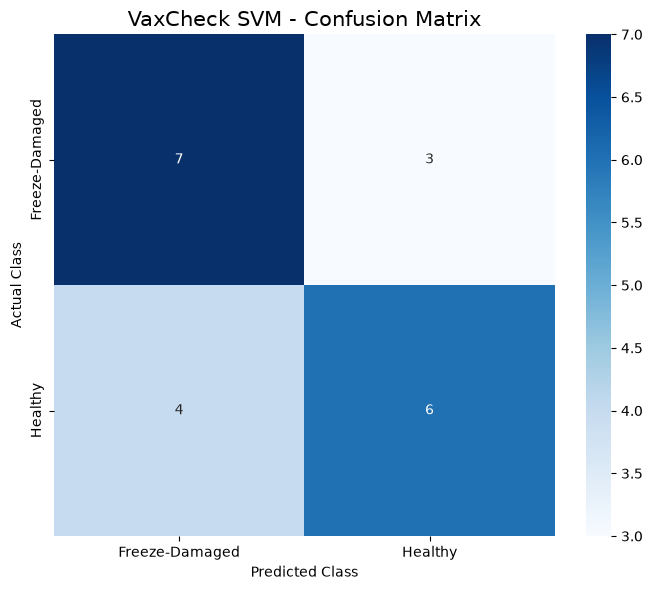

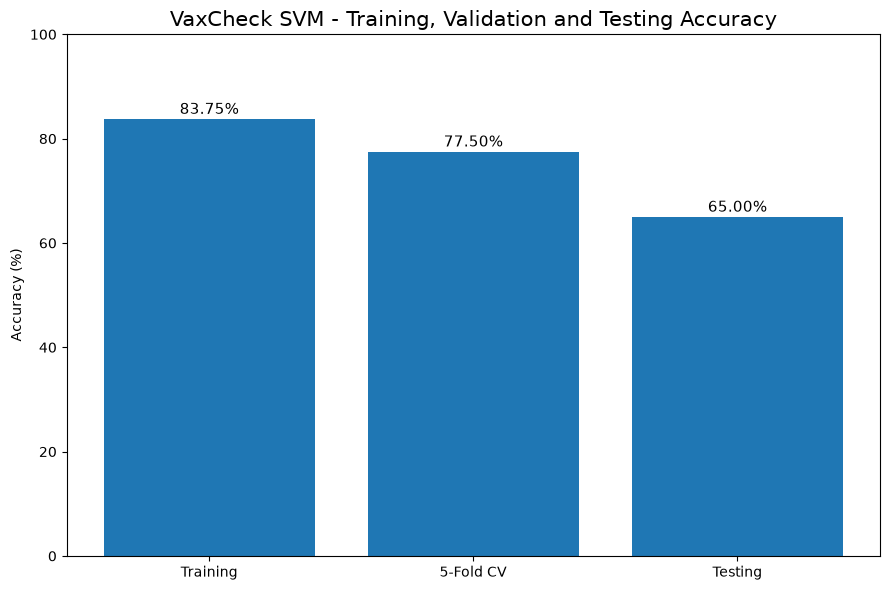

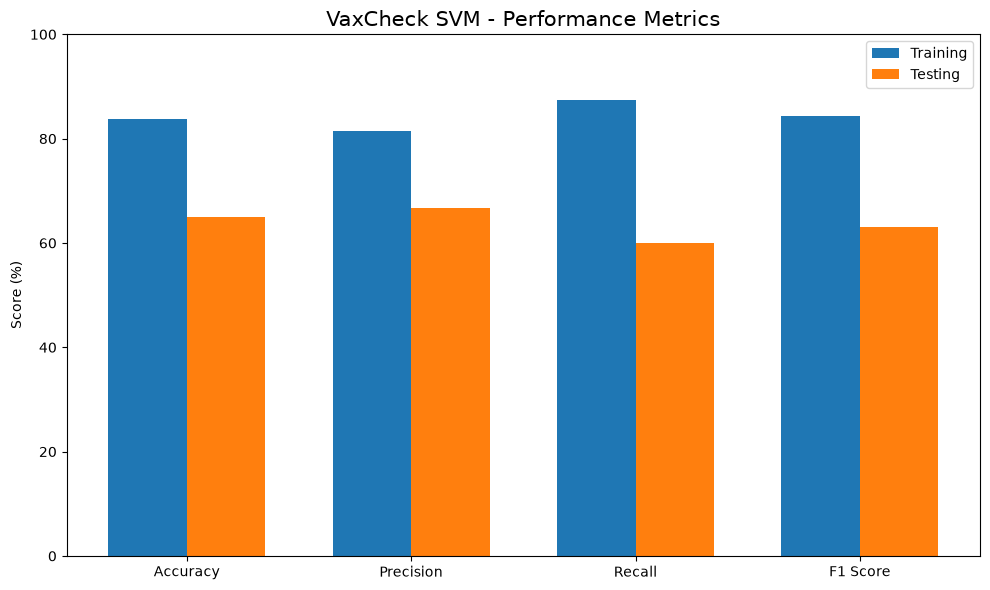

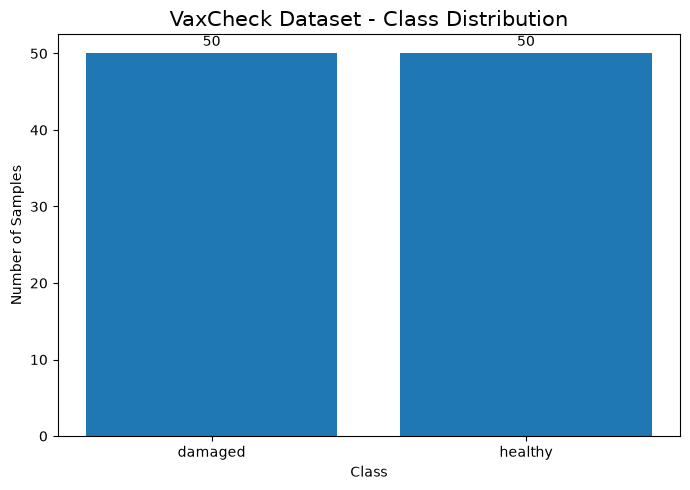

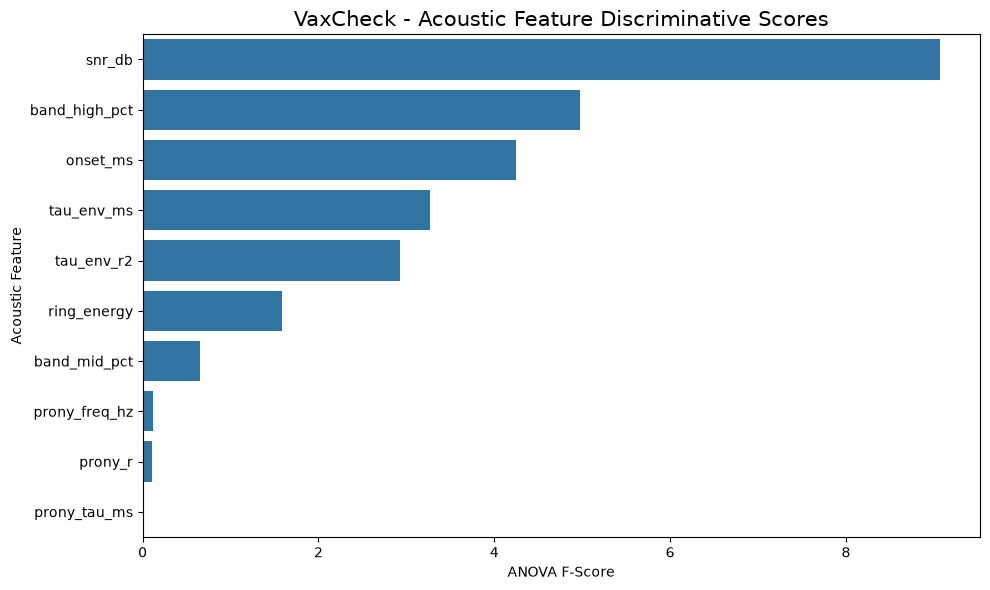


                     FINAL SUMMARY

Dataset Size          : 100
Training Samples      : 80
Testing Samples       : 20

MODEL PERFORMANCE
---------------------------------------------------------------------------
Training Accuracy     : 83.75%
5-Fold CV Accuracy    : 77.50%
Testing Accuracy      : 65.00%
Testing Precision     : 66.67%
Testing Recall        : 60.00%
Testing F1 Score      : 63.16%

Best Parameters:
{'feature_select__k': 9, 'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

                     MODEL SAVED
Saved as: vaxcheck_svm_best_practice.joblib

VaxCheck SVM training completed successfully.


In [10]:
# ============================================================
# VAXCHECK - BEST-PRACTICE SVM TRAINING
# Training + 5-Fold CV + Final Test + Metrics + Graphs
# ============================================================

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. LOAD DATA
# ============================================================

DATA_FILE = "features_all (9).csv"

df = pd.read_csv(DATA_FILE)

print("=" * 75)
print("                         VAXCHECK")
print("                    SVM CLASSIFIER")
print("=" * 75)

print("\nDATASET")
print("-" * 75)

print(f"File              : {DATA_FILE}")
print(f"Total samples     : {len(df)}")
print(f"Total columns     : {len(df.columns)}")

print("\nClass distribution:")
print(df["group"].value_counts())

# ============================================================
# 2. FEATURES
# ============================================================

features = [
    "onset_ms",
    "snr_db",
    "tau_env_ms",
    "tau_env_r2",
    "prony_freq_hz",
    "prony_tau_ms",
    "prony_r",
    "band_mid_pct",
    "band_high_pct",
    "ring_energy"
]

X = df[features].copy()

# Damaged = 0
# Healthy = 1

y = df["group"].map({
    "damaged": 0,
    "healthy": 1
})

if y.isna().any():
    raise ValueError(
        "Invalid values found in 'group'. "
        "Expected 'damaged' and 'healthy'."
    )

# ============================================================
# 3. DATA QUALITY
# ============================================================

print("\nMISSING VALUES")
print("-" * 75)

missing = X.isnull().sum()

if missing.sum() == 0:
    print("No missing values.")
else:
    print(missing[missing > 0])

print("\nDuplicate rows:", df.duplicated().sum())

# ============================================================
# 4. HOLD OUT TEST SET
# ============================================================
# IMPORTANT:
# The test set is not used during hyperparameter tuning.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("\nDATA SPLIT")
print("-" * 75)

print(f"Total samples     : {len(X)}")
print(f"Training samples  : {len(X_train)}")
print(f"Testing samples   : {len(X_test)}")

# ============================================================
# 5. SVM PIPELINE
# ============================================================

pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "feature_select",
        SelectKBest(score_func=f_classif)
    ),

    (
        "svm",
        SVC(
            probability=True,
            random_state=42
        )
    )
])

# ============================================================
# 6. HYPERPARAMETER SEARCH
# ============================================================

param_grid = {
    "feature_select__k": [
        6,
        7,
        8,
        9,
        10
    ],

    "svm__kernel": [
        "rbf"
    ],

    "svm__C": [
        0.25,
        0.5,
        1,
        2,
        5,
        10,
        20
    ],

    "svm__gamma": [
        "scale",
        0.003,
        0.01,
        0.03,
        0.1
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# ============================================================
# 7. TRAIN / TUNE
# ============================================================

print("\n" + "=" * 75)
print("                     MODEL TRAINING")
print("=" * 75)

print("\nStarting SVM hyperparameter tuning...")

grid.fit(X_train, y_train)

model = grid.best_estimator_

# ============================================================
# 8. BEST MODEL
# ============================================================

print("\n" + "=" * 75)
print("                       BEST MODEL")
print("=" * 75)

print("\nBest parameters:")

for key, value in grid.best_params_.items():
    print(f"{key}: {value}")

cv_accuracy = grid.best_score_

print(
    f"\nBest 5-Fold CV Accuracy : "
    f"{cv_accuracy * 100:.2f}%"
)

# ============================================================
# 9. TRAINING PREDICTIONS
# ============================================================

train_pred = model.predict(X_train)

# ============================================================
# 10. TRAINING METRICS
# ============================================================

train_accuracy = accuracy_score(
    y_train,
    train_pred
)

train_precision = precision_score(
    y_train,
    train_pred,
    zero_division=0
)

train_recall = recall_score(
    y_train,
    train_pred,
    zero_division=0
)

train_f1 = f1_score(
    y_train,
    train_pred,
    zero_division=0
)

train_correct = int(
    np.sum(train_pred == y_train)
)

train_wrong = len(y_train) - train_correct

# ============================================================
# 11. TEST PREDICTIONS
# ============================================================

test_pred = model.predict(X_test)

# ============================================================
# 12. TEST METRICS
# ============================================================

test_accuracy = accuracy_score(
    y_test,
    test_pred
)

test_precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    test_pred,
    zero_division=0
)

test_correct = int(
    np.sum(test_pred == y_test)
)

test_wrong = len(y_test) - test_correct

# ============================================================
# 13. TRAINING RESULTS
# ============================================================

print("\n" + "=" * 75)
print("                    TRAINING RESULTS")
print("=" * 75)

print(f"Training Samples : {len(y_train)}")
print(f"Correct          : {train_correct}")
print(f"Incorrect        : {train_wrong}")

print("\nTraining Metrics")
print("-" * 75)

print(f"Accuracy         : {train_accuracy * 100:.2f}%")
print(f"Precision        : {train_precision * 100:.2f}%")
print(f"Recall           : {train_recall * 100:.2f}%")
print(f"F1 Score         : {train_f1 * 100:.2f}%")

# ============================================================
# 14. TESTING RESULTS
# ============================================================

print("\n" + "=" * 75)
print("                     TEST RESULTS")
print("=" * 75)

print(f"Testing Samples  : {len(y_test)}")
print(f"Correct          : {test_correct}")
print(f"Incorrect        : {test_wrong}")

print("\nTesting Metrics")
print("-" * 75)

print(f"Accuracy         : {test_accuracy * 100:.2f}%")
print(f"Precision        : {test_precision * 100:.2f}%")
print(f"Recall           : {test_recall * 100:.2f}%")
print(f"F1 Score         : {test_f1 * 100:.2f}%")

# ============================================================
# 15. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_pred
)

print("\n" + "=" * 75)
print("                   CONFUSION MATRIX")
print("=" * 75)

print(cm)

print("\n                 Predicted")
print("                Damaged  Healthy")
print(
    f"Actual Damaged     {cm[0,0]:3d}      {cm[0,1]:3d}"
)
print(
    f"Actual Healthy     {cm[1,0]:3d}      {cm[1,1]:3d}"
)

# ============================================================
# 16. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 75)
print("                CLASSIFICATION REPORT")
print("=" * 75)

print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "Freeze-Damaged",
            "Healthy"
        ],
        zero_division=0
    )
)

# ============================================================
# 17. GRAPH 1 - CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Freeze-Damaged",
        "Healthy"
    ],
    yticklabels=[
        "Freeze-Damaged",
        "Healthy"
    ]
)

plt.title(
    "VaxCheck SVM - Confusion Matrix",
    fontsize=15
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

# ============================================================
# 18. GRAPH 2 - TRAINING / CV / TESTING
# ============================================================

labels = [
    "Training",
    "5-Fold CV",
    "Testing"
]

values = [
    train_accuracy * 100,
    cv_accuracy * 100,
    test_accuracy * 100
]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    labels,
    values
)

plt.title(
    "VaxCheck SVM - Training, Validation and Testing Accuracy",
    fontsize=15
)

plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

# ============================================================
# 19. GRAPH 3 - ALL METRICS
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

train_values = [
    train_accuracy * 100,
    train_precision * 100,
    train_recall * 100,
    train_f1 * 100
]

test_values = [
    test_accuracy * 100,
    test_precision * 100,
    test_recall * 100,
    test_f1 * 100
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    train_values,
    width,
    label="Training"
)

plt.bar(
    x + width / 2,
    test_values,
    width,
    label="Testing"
)

plt.title(
    "VaxCheck SVM - Performance Metrics",
    fontsize=15
)

plt.ylabel("Score (%)")
plt.xticks(x, metrics)
plt.ylim(0, 100)
plt.legend()

plt.tight_layout()
plt.show()

# ============================================================
# 20. GRAPH 4 - DATASET DISTRIBUTION
# ============================================================

plt.figure(figsize=(7, 5))

class_counts = df["group"].value_counts()

bars = plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title(
    "VaxCheck Dataset - Class Distribution",
    fontsize=15
)

plt.xlabel("Class")
plt.ylabel("Number of Samples")

for bar, value in zip(
    bars,
    class_counts.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        str(value),
        ha="center"
    )

plt.tight_layout()
plt.show()

# ============================================================
# 21. GRAPH 5 - FEATURE IMPORTANCE BY F-SCORE
# ============================================================
# This is feature-selection score, not SVM importance.

selector = model.named_steps["feature_select"]

scores = selector.scores_

feature_scores = pd.DataFrame({
    "Feature": features,
    "F_Score": scores
}).sort_values(
    "F_Score",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_scores,
    x="F_Score",
    y="Feature"
)

plt.title(
    "VaxCheck - Acoustic Feature Discriminative Scores",
    fontsize=15
)

plt.xlabel("ANOVA F-Score")
plt.ylabel("Acoustic Feature")

plt.tight_layout()
plt.show()

# ============================================================
# 22. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("                     FINAL SUMMARY")
print("=" * 75)

print(f"\nDataset Size          : {len(df)}")
print(f"Training Samples      : {len(X_train)}")
print(f"Testing Samples       : {len(X_test)}")

print("\nMODEL PERFORMANCE")
print("-" * 75)

print(
    f"Training Accuracy     : "
    f"{train_accuracy * 100:.2f}%"
)

print(
    f"5-Fold CV Accuracy    : "
    f"{cv_accuracy * 100:.2f}%"
)

print(
    f"Testing Accuracy      : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Testing Precision     : "
    f"{test_precision * 100:.2f}%"
)

print(
    f"Testing Recall        : "
    f"{test_recall * 100:.2f}%"
)

print(
    f"Testing F1 Score      : "
    f"{test_f1 * 100:.2f}%"
)

print("\nBest Parameters:")
print(grid.best_params_)

# ============================================================
# 23. SAVE MODEL
# ============================================================

MODEL_FILE = "vaxcheck_svm_best_practice.joblib"

joblib.dump(
    model,
    MODEL_FILE
)

print("\n" + "=" * 75)
print("                     MODEL SAVED")
print("=" * 75)

print(f"Saved as: {MODEL_FILE}")

print("\nVaxCheck SVM training completed successfully.")